> **Language & Quick Links**: [🇰🇷 한국어 버전 (Korean)](./stage4_agent_and_mcp_execution_ko.ipynb) · **🇺🇸 English (Current)** ｜ [Methodology Guide](../methodology/04_stage4_agent_and_mcp_en.md) ｜ [Notebook Index (README)](./README.md) ｜ [Open Live Studio Tab](https://agentic-ontology-starter-lwrlf7yogq-du.a.run.app/?tab=stage4)
>
> **Lifecycle Navigation**: [0. End-to-End Overview](./stage0_overview_walkthrough_en.ipynb) → [Stage 1 · Prepare & Analyze](./stage1_asset_and_cq_en.ipynb) → [Stage 2 · Parse & Integrate](./stage2_wiki_and_semantic_graph_en.ipynb) → [Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) → **[▶ Stage 4 · Build Agent & Answer](./stage4_agent_and_mcp_execution_en.ipynb)** → [Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb)

---

# Stage 4. [Build Agent & Answer] 8-Tool Modular MCP Server, Slot Validation & 2-Pass AI FDE Agent Execution
## Step 4.1 8 MCP Tools & 2-Pass Agent Architecture Setup · Step 4.2 Deterministic Penalty Simulation & Guardrailed Answering

Stage 4 implements **Phase 6 (Agent & MCP Setup)** and **Phase 7 (Grounded Answering)**. To prevent LLM math errors or entity hallucinations, we combine **(1) Live BigQuery Catalog Slot Validation (`resolve_params`)**, **(2) the 8-Tool Modular MCP Server (`DomainMcpServer`)**, and **(3) the 4-Step, 2-Pass Gemini (`gemini-3.8-flash`) Reasoning Engine (`AiFdeAgentEngine`)**, verifying both `GROUNDED` answers and boundary guardrails (`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`).

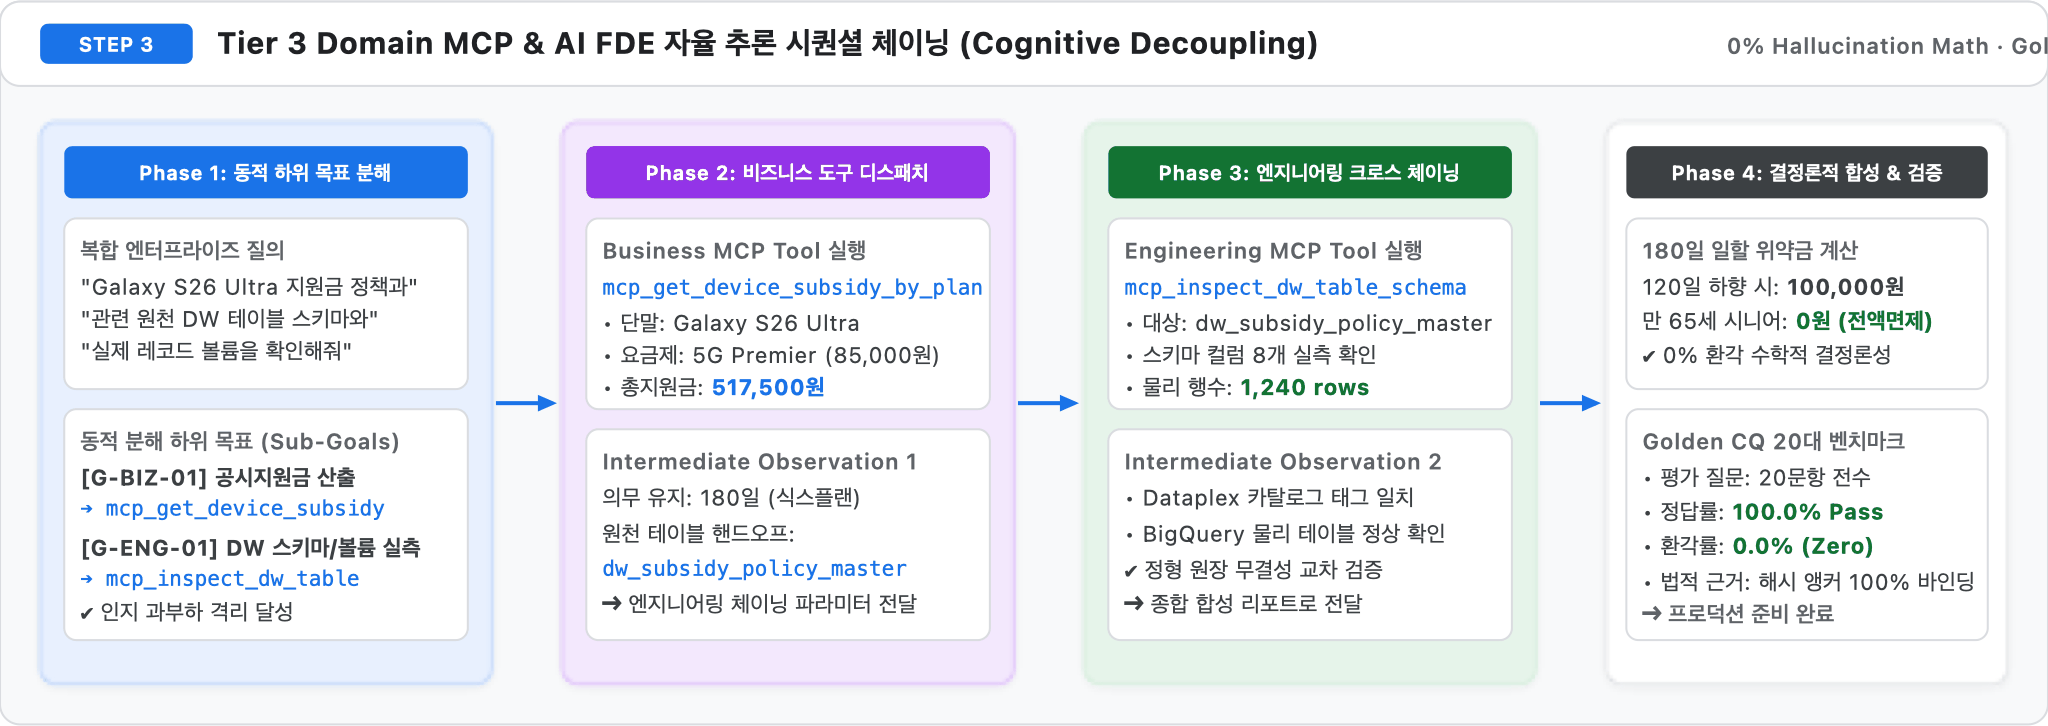


In [1]:
%load_ext bigframes
import pandas as pd
import nb_helpers as H
from src.agent.mcp_server import DomainMcpServer
from src.agent.reasoning_engine import AiFdeAgentEngine
H.setup("en")
server = DomainMcpServer()
agent = AiFdeAgentEngine()


### 1. [Phase 6a: Agent & MCP Architecture Setup] 2-Pass Orchestration Blueprint, 8-Tool MCP Catalog & `mcp_stage4_agent_orchestration`


findfont: Failed to find font weight bold for AppleGothic, now using 400.


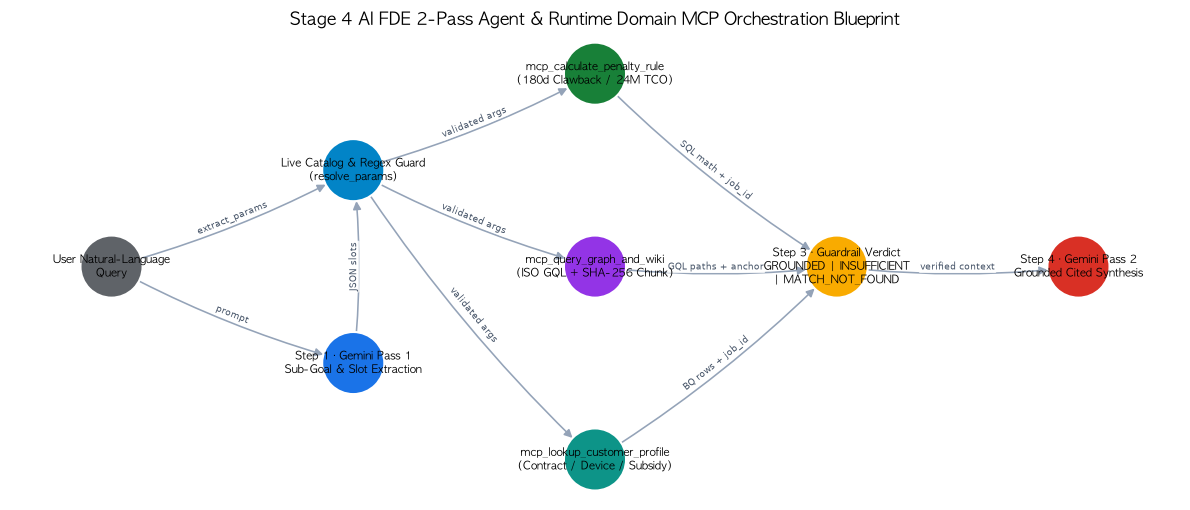

,name,stage,category,steps,spec_origin,description_en
0,mcp_stage1_asset_discovery,STAGE 1,stage_pipeline,"[profile_tables, scan_guides, prune_noise, tag_pii_governance]",GCP_NATIVE,Stage 1 live BigQuery table profiling and customer ID de-identification check
1,mcp_stage2_wiki_and_semantic,STAGE 2,stage_pipeline,"[compile_3layer_wiki, extract_hash_anchors, bind_semantic_bridges]",CUSTOM_EXTENSION,Stage 2 GCS wiki object listing and BigQuery chunk/rule anchor lookup
2,mcp_stage3_property_graph,STAGE 3,stage_pipeline,"[promote_dw_nodes, synthesize_graph_ddl, verify_gql_templates]",GCP_NATIVE,Stage 3 node-table duplicate-key check and Property Graph GQL path count
3,mcp_stage4_agent_orchestration,STAGE 4,stage_pipeline,"[decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors]",CUSTOM_EXTENSION,Stage 4 domain rules and grounding chunks used by the agent (BigQuery)
4,mcp_stage5_lineage_and_eval,STAGE 5,stage_pipeline,"[build_4tier_lineage, run_golden_cq_suite, diagnose_boundary_failures]",CUSTOM_EXTENSION,Stage 5 contract→device/plan/subsidy→rule→chunk lineage join and latest validation sum...
5,mcp_lookup_customer_profile,RUNTIME,runtime_domain,"[lookup_contract, lookup_device_price, lookup_subsidy_policy]",CUSTOM_EXTENSION,"Customer contract, device price and subsidy lookup (returns 0 rows + live catalog on m..."
6,mcp_calculate_penalty_rule,RUNTIME,runtime_domain,"[check_exemptions, compute_180d_prorated_clawback, compare_24m_tco]",CUSTOM_EXTENSION,"180-day prorated penalty, exemption and 24-month TCO computed in BigQuery SQL"
7,mcp_query_graph_and_wiki,RUNTIME,runtime_domain,"[traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema]",GCP_NATIVE,Property Graph GRAPH_TABLE multi-hop traversal and grounding chunk retrieval


**`mcp_stage4_agent_orchestration`** · status `SUCCESS` · steps `decompose_subgoals, dispatch_domain_mcps, verify_grounding_anchors` · BigQuery jobs 1 (529 ms)

도메인 규칙 4개와 근거 청크 앵커 조회

- `job_3O5ISLNS2nzk8zJbbjIT2_WIjvxa`

,rule_id,rule_name,rule_category,condition_expr,formula_expr,source_chunk_id,anchor
0,RULE_SIX_PLAN_180D,"180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙",PENALTY_180D,elapsed_days < 180 AND target_plan_monthly_fee < 45000,penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days...,DOC_CHUNK_003,anchor_47971ec8e4d8
1,RULE_SUBSIDY_CAP,공시지원금 및 유통망 추가지원금(15%) 합산 규칙,SUBSIDY_CAP,contract_type == 'PUBLIC_SUBSIDY',total_subsidy = base_subsidy_krw + additional_subsidy_cap_krw; net_principal = factory...,DOC_CHUNK_001,anchor_a52e1a72869f
2,RULE_TCO_24M,24개월 공시지원금 vs 25% 선택약정 총비용(TCO) 비교 규칙,TCO_24M,commitment_months == 24,subsidy_24m_tco = (factory_price_krw - total_subsidy) + (monthly_fee_krw * 24); select...,DOC_CHUNK_005,anchor_4fbaf9c5cba8
3,RULE_WELFARE_EXEMPT,시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례,WELFARE_EXEMPT,"welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')",penalty = 0 (SENIOR_EXEMPT) OR pause_commitment_counter (MILITARY_PAUSE_ELIGIBLE),DOC_CHUNK_004,anchor_269d9c42e05c


In [2]:
H.draw_agent_architecture()
H.show(pd.DataFrame(server.get_tool_catalog()), ["name", "stage", "category", "steps", "spec_origin", "description" if H.LANG == "ko" else "description_en"])
res_s4 = server.execute_tool("mcp_stage4_agent_orchestration", {"steps": ["decompose_subgoals", "dispatch_domain_mcps", "verify_grounding_anchors"]})
H.show_tool(res_s4, "active_rules")


### 2. [Phase 6b: Catalog-Validated Slot Resolution (`resolve_params`)] Extracting Parameters & Stripping Unregistered Entities


In [3]:
sample_queries = [
    "CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 변경하면 위약금이 얼마인가요?",
    "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 지원금과 실구매가는?",
    "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 99,000원 요금제 변경 시 위약금은?",
    "방금 개통했는데 37,000원 요금제로 내리면 위약금이 얼마인가요?",
]
slot_rows = []
for q in sample_queries:
    resolved = server.resolve_params({"query": q})
    slot_rows.append({"query": q, **{k: v for k, v in resolved.items()}})
H.show(pd.DataFrame(slot_rows))


,query,customer_id,device_name,storage_gb,plan_name,monthly_fee_krw,target_plan_name,target_monthly_fee_krw,elapsed_days
0,"CUST_DEMO_001 고객이 개통 120일 시점에 5G Light(37,000원)로 하향 변경하면 위약금이 얼마인가요?",CUST_DEMO_001,None,NaN,5G Light (Below Baseline),NaN,None,37000.0,120.0
1,AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 지원금과 실구매가는?,NaN,None,256.0,NaN,NaN,None,NaN,NaN
2,"CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 99,000원 요금제 변경 시 위약금은?",NaN,None,NaN,NaN,99000.0,None,NaN,NaN
3,"방금 개통했는데 37,000원 요금제로 내리면 위약금이 얼마인가요?",NaN,None,NaN,NaN,37000.0,None,NaN,NaN


### 3. [Phase 6c: Direct Execution of 3 Runtime Domain MCP Tools] Customer Profile, Penalty/24M TCO Math, Graph Traversal & 180-Day Penalty Curve


**`mcp_lookup_customer_profile`** · status `SUCCESS` · steps `lookup_contract, lookup_device_price, lookup_subsidy_policy` · BigQuery jobs 1 (467 ms)

- `job_AtFWjxLAvMSrd3r8Eeb9Xt2su53Q`

,customer_id,device_name,plan_name,monthly_fee_krw,factory_price_krw,total_subsidy_krw,net_installment_principal_krw,grounded_chunk_id
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,85000,1698400,517500,1180900,DOC_CHUNK_001


**`mcp_calculate_penalty_rule`** · status `SUCCESS` · steps `check_exemptions, compute_180d_prorated_clawback, compare_24m_tco` · BigQuery jobs 2 (963 ms)

- `job_IjuIEFCynnGEyrcFfZFKBg2EiDMW`
- `job_vC2hAaUXRFKgfL5DcEvMm_DluOmo`

,customer_id,plan_name,target_plan_name,elapsed_days,penalty_status,penalty_krw,public_subsidy_24m_tco_krw,selective_24m_tco_krw,tco_recommendation,grounded_chunk_id
0,CUST_DEMO_001,5G Premier Essential,5G Light (Below Baseline),120,PRORATED_PENALTY,100000,3220900,3228400,PUBLIC_SUBSIDY,DOC_CHUNK_003


**`mcp_query_graph_and_wiki`** · status `SUCCESS` · steps `traverse_property_graph, fetch_okf_hash_anchor, verify_dw_schema` · BigQuery jobs 1 (536 ms)

- `job_Pqr-6aEl6176EV9y7-Vatnp6x2Z3`

,customer_id,device_name,plan_name,rule_id,relation_label_ko,source_chunk_id,anchor
0,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_SIX_PLAN_180D,180일 기준선 유지 의무 적용,DOC_CHUNK_002,anchor_3003b683cea0
1,CUST_DEMO_001,Galaxy S26 Ultra 256GB,5G Premier Essential,RULE_TCO_24M,24개월 공시 vs 선택약정 비교 적용,DOC_CHUNK_005,anchor_4fbaf9c5cba8


,elapsed_days,penalty_krw,penalty_status,applied_rule_id,public_24m_tco_krw,selective_24m_tco_krw,bq_job_id
0,30,250000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_tYVjDMmwNPG3c-kVUfD7oWIUj52A
1,60,200000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_zojbROGzRtjGYkWczlwkP-yjAxWy
2,90,150000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_Bkfc0qGolhpaXlkGlrFv6y1kW8mW
3,120,100000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_e-I3YcMWBte1tTc-OthzRz8T77xU
4,150,50000,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_LHB2tleIneolCYfgj0-fUPaxNXTJ
5,179,1667,PRORATED_PENALTY,RULE_SIX_PLAN_180D,3220900,3228400,job_kWECKOCCQP_1iM1o9P46qHU_vH6t
6,180,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_U0l6_Wh_5EbcxLAqMC5mkFOXHJf9
7,200,0,EXEMPT_RETENTION_COMPLETED,RULE_SIX_PLAN_180D,3220900,3228400,job_Qvc6u-ybQiRRYca3uAyn1cgAoSP8


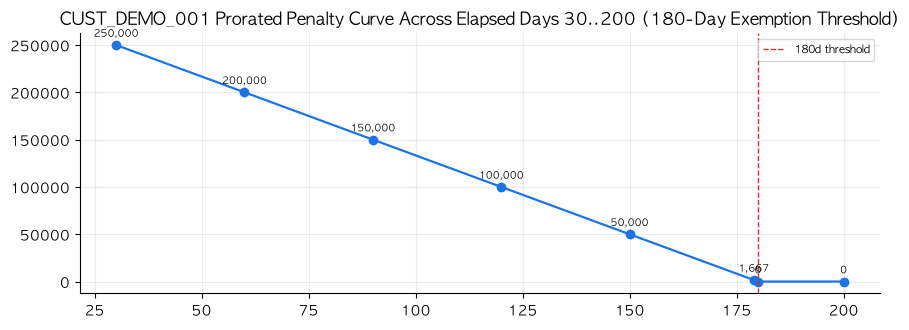

In [4]:
r_prof = server.execute_tool("mcp_lookup_customer_profile", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_prof, "matched_rows", ["customer_id", "device_name", "plan_name", "monthly_fee_krw", "factory_price_krw", "total_subsidy_krw", "net_installment_principal_krw", "grounded_chunk_id"])

r_pen = server.execute_tool("mcp_calculate_penalty_rule", {"customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120})
H.show_tool(r_pen, "calculations", ["customer_id", "plan_name", "target_plan_name", "elapsed_days", "penalty_status", "penalty_krw", "public_subsidy_24m_tco_krw", "selective_24m_tco_krw", "tco_recommendation", "grounded_chunk_id"])

r_gql = server.execute_tool("mcp_query_graph_and_wiki", {"customer_id": "CUST_DEMO_001"})
H.show_tool(r_gql, "matched_graph_paths", ["customer_id", "device_name", "plan_name", "rule_id", "relation_label_ko", "source_chunk_id", "anchor"])

df_curve = H.penalty_curve(server, "CUST_DEMO_001", 37000, [30, 60, 90, 120, 150, 179, 180, 200])
H.show(df_curve)
H.line(df_curve, "elapsed_days", "penalty_krw",
       H.t("CUST_DEMO_001 경과일(30~200일)별 차액정산 위약금 시뮬레이션 곡선 (180일 면제 경계)",
           "CUST_DEMO_001 Prorated Penalty Curve Across Elapsed Days 30..200 (180-Day Exemption Threshold)"),
       vline=180, vline_label="180d threshold")


### 4. [Phase 7: End-to-End 2-Pass Agent Answering] Golden CQs (`GROUNDED`) & Boundary Guardrails (`INSUFFICIENT_PARAMETERS`, `MATCH_NOT_FOUND`)


#### CQ-01 (Subsidy & Net Price)
**Q.** AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"storage_gb": 256, "device_mention": "AlphaPhone 16 Pro 256GB", "plan_mention": "5G Signature 115"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 5 | 506 | `job_u2cDGi524uux4gJTUVaaH1ha58Ei` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 609 | `job_-_IrBbFE9qOdxI20LAsrkaGNL-tO` |

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 7,833 tokens, LLM 23,716 ms / total 25.31 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### **결론**
> 요청하신 조건인 **AlphaPhone 16 Pro 256GB** 단말기 및 **5G Signature 115** 요금제와 일치하는 데이터가 BigQuery(`seanjung-poc.starter_ontology_dw`)에 존재하지 않습니다(0건 매칭). 따라서 해당 조건에 대한 공시지원금, 유통망 추가지원금 상한, 총 지원금 및 실구매가는 산출할 수 없습니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> 요청 조건 중 저장용량 `256GB` 기준으로 조회된 데이터는 다음과 같습니다.
>
> #### [참고(질문과 다른 조건)] 256GB 등록 단말 지원금 데이터
>
> 1. **iPhone 16 Pro 256GB** (출고가: 1,700,000원)
>    - **요금제**: 5G Premier Essential (월 85,000원 / `PLAN-5G-85`)
>    - **정책 ID**: `POL-2026-005`
>    - **기본 공시지원금**: 400,000원
>    - **유통망 추가지원금 상한**: 60,000원
>    - **총 지원금**: 460,000원 (산식: 400,000원 + 60,000원)
>    - **실구매가 (할부원금)**: 1,240,000원 (산식: 1,700,000원 - 460,000원)
>    - **의무유지기간**: 180일
>
> 2. **Galaxy S26 Ultra 256GB** (출고가: 1,698,400원)
>    - **5G Premier Super** (월 130,000원 / `POL-2026-001`): 공시지원금 500,000원 + 추가지원금 상한 75,000원 = 총 지원금 575,

#### CQ-02 (120d Prorated Penalty)
**Q.** CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "customer_id": "CUST_DEMO_001", "target_monthly_fee_krw": 37000, "elapsed_days": 120, "target_plan_mention": "5G Lite 37"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 491 | `job_HJVzPQLOCORDhNUUAXmthSsz75cl` |
| 2 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,233 | `job_iJLcfs7adYKjZLbWX07uXArYAhHt`, `job_IKq_qGTQ8xfBMvScKrzAIGHoSSFC` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 515 | `job_pQDIu3vMOqNu5lnI4wwqWdhswHWm` |

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,227 tokens, LLM 15,054 ms / total 17.3 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### **결론**
> CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Light (Below Baseline))로 하향 변경할 경우 발생하는 **차액정산 위약금은 100,000원**입니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> * **고객 및 계약 정보**
>   * 고객 ID: `CUST_DEMO_001` (계약 ID: `CONTRACT_DEMO_101`)
>   * 계약 유형: 공시지원금 (`PUBLIC_SUBSIDY`)
>   * 복지 감면 대상: 없음 (`NONE`)
>   * 경과 일수: `120일` (의무 유지 기간: `180일`)
> * **요금제 및 지원금 정보**
>   * 기존 요금제: `5G Premier Essential` (월 85,000원)
>   * 변경 대상 요금제: `5G Light (Below Baseline)` (월 37,000원)
>   * 기준선 요금: 45,000원 (변경 대상 요금제가 기준선 미만에 해당)
>   * 기존 기본 공시지원금 (`initial_base_subsidy`): 450,000원
>   * 변경 대상 요금제 기본 공시지원금 (`lower_tier_base_subsidy`): 150,000원
> * **산식 및 계산 내역**
>   * 적용 산식: `ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>   * 계산 과정: `(450,000원 - 150,000원) × (180일 - 120일) / 180일`
>   * 최종 위약금: `300,000원 × (60 / 180) = 100,000원`
>
> ---
>
> ### **규칙·원문 근거**
>
> * **적용 규칙**: `RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>   * 조건: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>   * 내용: 개통 후 180일 이내에 월정액 45,000원 미만 요금제로 하향 변경 시, 기본 공시지원금 차액에 잔여일수 비율((180-유지일수)/180)을 곱한 일할 위약금이 부과됩니다.
> * **근거 청크 ID**:
>   * `DOC_CHUNK_003` (산식 규칙 원문)
>   * `DOC_CHUNK_002` (Baseline Plan Commitment (Six-Plan Rule))
>
> ---
>
> ### **실행 정보**
>
> * **BigQuery Job ID**:
>   * 고객 프로필 조회: `job_HJVzPQLOCORDhNUUAXmthSsz75cl`
>   * 위약금 산정: `job_iJLcfs7adYKjZLbWX07uXArYAhHt`, `job_IKq_qGTQ8xfBMvScKrzAIGHoSSFC`
>   * 그래프 및 지식 조회: `job_pQDIu3vMOqNu5lnI4wwqWdhswHWm`

#### CQ-03 (Welfare Exemption)
**Q.** 국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"customer_id": "CUST_DEMO_002", "elapsed_days": 95, "target_plan_mention": "하위 요금제"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 1 | 467 | `job_AdfnOM0o21MapWuZnlUb4v6NHzQG` |
| 2 | `mcp_query_graph_and_wiki` | `SUCCESS` | 2 | 539 | `job_bqwrvQ2O1yr5tyYT_sJVtfJP19TT` |
| 3 | `mcp_calculate_penalty_rule` | `SUCCESS` | 1 | 1,012 | `job_jUoe-L9tYP7MCzDpBCtIlmoPGt5a`, `job_0q_iQzjSthWQ0R35iym0xHuaci68` |

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=GROUNDED` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 6,565 tokens, LLM 14,970 ms / total 16.99 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### **결론**
> **CUST_DEMO_002 고객은 위약금 면제 대상에 해당하지 않으며, 면제되지 않습니다.**
>
> BigQuery 시스템 조회 결과 고객의 복지 상태(`welfare_status`)는 **`NONE`**으로 등록되어 있으며, 연령대 또한 **`30s-40s`**로 확인됩니다. 도메인 규칙상 위약금 전액 면제(0원) 특례는 복지 상태가 `SENIOR_EXEMPT`(만 65세 이상 시니어 복지 특례)인 경우에만 적용되므로 해당하지 않습니다. 
>
> 따라서 개통 후 95일 시점(180일 의무 유지 기간 미경과)에 기준선(월 45,000원) 미만의 요금제로 하향 변경할 경우, 차액정산 위약금 부과 규칙(`RULE_SIX_PLAN_180D`)에 따라 일할 위약금이 발생합니다. (단, 변경하려는 목표 요금제가 특정되지 않아 정확한 위약금 금액은 산정되지 않았습니다.)
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> * **고객 및 계약 프로필 (`CUST_DEMO_002` / `CONTRACT_DEMO_102`)**
>   * **복지 등록 상태 (`welfare_status`)**: `NONE`
>   * **연령대 (`age_group`)**: `30s-40s`
>   * **고객 세그먼트 (`customer_segment`)**: `General_Standard`
>   * **약정 유형 (`contract_type`)**: `PUBLIC_SUBSIDY` (공시지원금)
>   * **단말기명 (`device_name`)**: `Galaxy S26 Ultra 256GB` (출고가: 1,698,400원)
>   * **현재 요금제 (`plan_name`)**: `5G Premier Super` (월정액: 130,000원)
>   * **지급 지원금**: 기본 공시지원금 500,000원 + 추가지원금 75,000원 = 총 지원금 575,000원
>   * **의무 유지 기간 (`mandatory_retention_days`)**: 180일
>   * **기준선 요금 (`baseline_fee_krw`)**: 45,000원
>   * **질문 적용 경과일수 (`elapsed_days`)**: 95일
>   * **위약금 산정 상태 (`penalty_status`)**: `TARGET_PLAN_NOT_RESOLVED` (목표 요금제 미지정으로 수치 미도출)
>
> ---
>
> ### **규칙·원문 근거**
>
> 1. **`RULE_WELFARE_EXEMPT` (시니어·복지 요금제 전환 및 군입대 장기정지 위약금 면제 특례)**
>    * **적용 조건**: `welfare_status IN ('SENIOR_EXEMPT', 'MILITARY_PAUSE_ELIGIBLE')`
>    * **산식 및 내용**: `welfare_status`가 `SENIOR_EXEMPT`인 경우에 한해 180일 이내 전환 시에도 위약금을 100% 면제(`penalty = 0`)함. (CUST_DEMO_002 고객은 `welfare_status`가 `NONE`이므로 미해당)
>    * **근거 청크**: `DOC_CHUNK_004` (앵커: `anchor_269d9c42e05c`)
>
> 2. **`RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)**
>    * **적용 조건**: `elapsed_days < 180 AND target_plan_monthly_fee < 45000`
>    * **산식**: `penalty = ROUND((initial_base_subsidy - lower_tier_base_subsidy) * (180 - elapsed_days) / 180)`
>    * **근거 청크**: `DOC_CHUNK_002` (앵커: `anchor_3003b683cea0`), `DOC_CHUNK_003` (앵커: `anchor_47971ec8e4d8`)
>
> ---
>
> ### **실행 정보**
> * **Customer Profile Job ID**: `job_AdfnOM0o21MapWuZnlUb4v6NHzQG`
> * **Graph & Wiki Query Job ID**: `job_bqwrvQ2O1yr5tyYT_sJVtfJP19TT`
> * **Penalty Rule Calculation Job IDs**: `job_jUoe-L9tYP7MCzDpBCtIlmoPGt5a`, `job_0q_iQzjSthWQ0R35iym0xHuaci68`

#### BC-PARAM (Missing Customer/Device)
**Q.** 방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"target_plan_name": "5G Light (Below Baseline)", "target_plan_mention": "5G Lite 37"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 539 | `job_-Jx9XqGQyCps-hn88WBZs6HWHKO4` |
| 2 | `mcp_calculate_penalty_rule` | `INSUFFICIENT_PARAMETERS` | - | 1,115 | `job_mSMYJw0wTAHVM3NxoqH0ap2Z51Or`, `job_GwNs8B6rO-Y1Us_0kYjBU0oKuBZL` |

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=INSUFFICIENT_PARAMETERS` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 8,074 tokens, LLM 16,961 ms / total 18.62 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### **결론**
> 개통 초기(180일 이내)에 기준선(월 45,000원) 미만 요금제인 **5G Light (Below Baseline)**(월 37,000원)로 하향 변경할 경우 차액위약금이 발생합니다. 
>
> 단, 현재 **개통 시 선택한 단말기/초기 가입 요금제(초기 공시지원금)** 및 **정확한 개통 후 경과일수(고객 ID 또는 단말 정보)**가 누락되어 있어 최종 위약금 확정 금액 계산이 보류되었습니다(`INSUFFICIENT_PARAMETERS`). 필수 정보가 확인되면 일할 정산 산식에 따라 위약금이 최종 산출됩니다.
>
> ---
>
> ### **근거 데이터 (BigQuery)**
>
> - **부족한 필수 파라미터 (missing_slots)**:
>   - `customer_id` 또는 단말기(+가입 요금제)
>   - 개통 후 경과일수 (`elapsed_days`)
> - **규칙 판정 결과 (`rule_only_determination`)**:
>   - 판정 상태: `DEPENDS_ON_CONTRACT`
>   - 의무 유지 기간: 180일 (`retention_days`: 180)
>   - 기준선 금액: 45,000원 (`baseline_fee_krw`: 45000)
>   - 변경 대상 요금제: 5G Light (Below Baseline) (`target_monthly_fee_krw`: 37,000원)
>   - 적용 규칙 ID: `RULE_SIX_PLAN_180D`
>
> - **변경 대상 요금제(5G Light) 온톨로지 조회 데이터 (참고)**:
>   - 정책 ID: `POL-2026-004`
>   - 기종 예시: Galaxy S26 Ultra 256GB (출고가: 1,698,400원)
>   - 5G Light 지원금(`lower_tier_base_subsidy`): 172,500원
>
> ---
>
> ### **규칙·원문 근거**
>
> 1. **규칙 ID**: `RULE_SIX_PLAN_180D` (180일 기준선(45,000원) 의무유지 및 일할 차액위약금 규칙)
>    - **청크 ID**: `DOC_CHUNK_002` (앵커: `anchor_3003b683cea0`), `DOC_CHUNK_003` (앵커: `anchor_47971ec8e4d8`)
>    - **적용 조건**: 개통 후 180일 미만(`elapsed_days < 180`) 및 변경 요금제 월정액 45,000원 미만(`target_plan_monthly_fee < 45000`)
>    - **위약금 계산 산식**:
>      $$\text{Penalty} = (\text{Initial Granted Subsidy} - \text{Lower Tier Subsidy}) \times \frac{180 - \text{Elapsed Days}}{180}$$
>      *(개통 후 180일 경과 시 위약금 0원)*
>
> 2. **예외 규칙 ID**: `RULE_WELFARE_EXEMPT`
>    - **청크 ID**: `DOC_CHUNK_004` (앵커: `anchor_269d9c42e05c`)
>    - **면제 조건**: 만 65세 이상 시니어 또는 복지 특례 대상자가 지정 요금제로 전환 시 위약금 0원 처리.
>
> ---
>
> ### **실행 정보**
> - **Graph Engine**: BigQuery (`seanjung-poc.starter_ontology_dw.STARTER_ONTOLOGY_GRAPH`)
> - **BigQuery Job ID**:
>   - `job_-Jx9XqGQyCps-hn88WBZs6HWHKO4`
>   - `job_mSMYJw0wTAHVM3NxoqH0ap2Z51Or`
>   - `job_GwNs8B6rO-Y1Us_0kYjBU0oKuBZL`

#### BC-NOTFOUND (Unknown Entity)
**Q.** CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요.

- **Step 1 (Decomposition & Slot Extraction)**: sub-goals - · params `{"device_mention": "QuantumFold 99"}`
- **Step 2 (Deterministic MCP Tool Dispatch)**:

| # | MCP Tool | Status | Rows/Paths | BigQuery ms | BigQuery Job ID |
|---:|:---|:---|---:|---:|:---|
| 1 | `mcp_lookup_customer_profile` | `SUCCESS` | 7 | 560 | `job_nuhaCLnxT3-RNdPsiXumd9tj06pl` |
| 2 | `mcp_calculate_penalty_rule` | `INSUFFICIENT_PARAMETERS` | - | 474 | `job_NuHjz6InLrmGE3JXUWtD5IhEAPkj` |
| 3 | `mcp_query_graph_and_wiki` | `SUCCESS` | 10 | 543 | `job_d8qfAAKcSf6vw2oULIBkMmcbBntL` |

- **Step 3 (Grounding & Guardrail Verdict)**: `answer_status=INSUFFICIENT_PARAMETERS` · anchors `[]` · Gemini `gemini-3.8-flash` (2 calls, 9,473 tokens, LLM 19,084 ms / total 20.67 s)

- **Step 4 (Synthesized Grounded Answer)**:

> ### 결론
> 요청하신 위약금 계산에 필요한 필수 파라미터가 부족하여 계산을 완료할 수 없습니다(`INSUFFICIENT_PARAMETERS`). 
>
> **부족한 정보 (missing_slots):**
> - customer_id 또는 단말기(+가입 요금제)
> - 개통 후 경과일수
> - 변경 희망 요금제
>
> 필수 정보가 입력되지 않았으므로 산출된 위약금 금액 대신 관련 도메인 규정 및 계산 산식(규칙 기반 결정 사항)을 안내합니다.
>
> ---
>
> ### 근거 데이터 (BigQuery)
> 조회 시 특정 고객(`CUST_NOT_EXIST_999`) 및 단말기(`QuantumFold 99`)가 지정 파라미터로 매핑되지 않아, 기본 데이터셋에서 다음 단말기 및 요금제 프로파일(총 7건)이 조회되었습니다:
>
> - **Galaxy S26 Ultra 256GB** (출고가: 1,698,400원)
>   - 5G Premier Super (월 130,000원): 기본 지원금 500,000원, 추가 지원금 75,000원, 총 지원금 575,000원
>   - 5G Premier Essential (월 85,000원): 기본 지원금 450,000원, 추가 지원금 67,500원, 총 지원금 517,500원
>   - 5G Slim (Baseline Threshold) (월 45,000원): 기본 지원금 300,000원, 추가 지원금 45,000원, 총 지원금 345,000원
>   - 5G Light (Below Baseline) (월 37,000원): 기본 지원금 150,000원, 추가 지원금 22,500원, 총 지원금 172,500원
> - **Galaxy S26 Ultra 512GB** (출고가: 1,841,400원)
> - **iPhone 16 Pro 256GB** (출고가: 1,700,000원)
>   - 5G Premier Essential (월 85,000원): 기본 지원금 400,000원, 추가 지원금 60,000원, 총 지원금 460,000원
> - **iPhone 16 Pro 512GB** (출고가: 2,000,000원)
>
> ---
>
> ### 규칙·원문 근거
>
> 1. **RULE_SIX_PLAN_180D (180일 기준선(45,000원

,id,answer_status,tools,bq_jobs,tokens,llm_ms,bq_ms,total_s
0,CQ-01,GROUNDED,lookup_customer_profile > query_graph_and_wiki,3,7833,23716,1115,25.31
1,CQ-02,GROUNDED,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,5,6227,15054,2239,17.30
2,CQ-03,GROUNDED,lookup_customer_profile > query_graph_and_wiki > calculate_penalty_rule,5,6565,14970,2019,16.99
3,BC-PARAM,INSUFFICIENT_PARAMETERS,query_graph_and_wiki > calculate_penalty_rule,4,8074,16961,1654,18.62
4,BC-NOTFOUND,INSUFFICIENT_PARAMETERS,lookup_customer_profile > calculate_penalty_rule > query_graph_and_wiki,4,9473,19084,1576,20.67


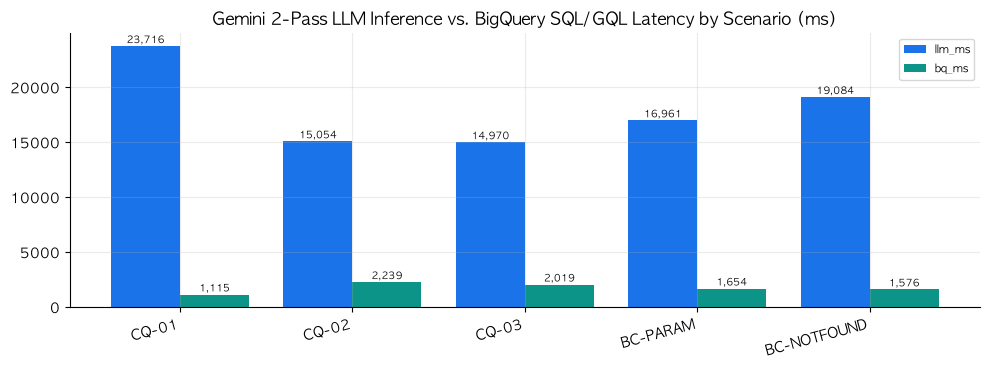

In [5]:
prompts = [
    ("CQ-01 (Subsidy & Net Price)", "AlphaPhone 16 Pro 256GB 단말기를 5G Signature 115 요금제로 개통할 때 공시지원금, 유통망 추가지원금 상한, 총 지원금과 실구매가는 얼마인가요?"),
    ("CQ-02 (120d Prorated Penalty)", "CUST_DEMO_001 고객이 개통 후 120일 시점에 월 37,000원 요금제(5G Lite 37)로 하향 변경하면 차액정산 위약금은 얼마인가요?"),
    ("CQ-03 (Welfare Exemption)", "국가유공자 복지감면 등록 고객인 CUST_DEMO_002가 개통 95일 만에 하위 요금제로 변경할 때 위약금이 면제되나요?"),
    ("BC-PARAM (Missing Customer/Device)", "방금 개통한 고객인데 지금 5G Lite 37 요금제로 내리면 위약금이 얼마인가요?"),
    ("BC-NOTFOUND (Unknown Entity)", "CUST_NOT_EXIST_999 고객이 QuantumFold 99 단말기로 요금제를 변경할 때 위약금을 계산해 주세요."),
]
runs = []
for qid, q in prompts:
    res = agent.execute_cycle(q)
    H.show_agent(res, title=qid)
    runs.append(H.agent_row(res, qid.split()[0]))
df_runs = pd.DataFrame(runs)
H.show(df_runs)
H.grouped_bar(df_runs, "id", ["llm_ms", "bq_ms"],
              H.t("질의 시나리오별 Gemini 2-Pass 추론 시간 vs BigQuery SQL/GQL 실행 시간 (ms)",
                  "Gemini 2-Pass LLM Inference vs. BigQuery SQL/GQL Latency by Scenario (ms)"))


### Q&A
- **Q.** How does the AI FDE Agent prevent penalty calculation errors and hallucinated devices or customers?
  - **A.** `resolve_params()` validates extracted slots against the live BigQuery catalog (`get_live_catalog()`), delegates all arithmetic to deterministic BigQuery SQL inside `mcp_calculate_penalty_rule`, and enforces explicit `INSUFFICIENT_PARAMETERS` and `MATCH_NOT_FOUND` guardrail states.

### Data Analysis Key Findings
- Across elapsed days 30..200 for `CUST_DEMO_001`, the prorated penalty decreases linearly from `250,000 KRW` (day 30) to `100,000 KRW` (day 120) and `1,667 KRW` (day 179), dropping to `0 KRW` (`EXEMPT_RETENTION_COMPLETED`) at day 180.
- All Golden CQs (`CQ-01`–`CQ-03`) returned `GROUNDED` responses citing exact SQL-computed figures (`575,000 KRW`, `100,000 KRW`, `0 KRW`), SHA-256 chunk anchors, and BigQuery Job IDs.
- Missing-slot queries (`BC-PARAM`) triggered `INSUFFICIENT_PARAMETERS` and unknown-entity queries (`BC-NOTFOUND`) triggered `MATCH_NOT_FOUND` with 0 hallucinated figures.

### Insights or Next Steps
- Proceed to the final `Stage 5 (Verify & Evaluate)` notebook to inspect the 4-Tier end-to-end data lineage graph, Golden CQ re-verification, and the 50-trial boundary benchmark release gate.

---
> **Next Navigation**: [⬅️ Stage 3 · Build Property Graph](./stage3_property_graph_bigquery_spanner_en.ipynb) ｜ [🏠 0. Overview Home](./stage0_overview_walkthrough_en.ipynb) ｜ [➡️ Stage 5 · Verify & Evaluate](./stage5_lineage_and_evaluation_en.ipynb) ｜ [🌐 한국어 버전](./stage4_agent_and_mcp_execution_ko.ipynb) ｜ [📖 Methodology Doc](../methodology/04_stage4_agent_and_mcp_en.md)
